In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

file_path = r"F:\25.2F HND\ML CW\fish_price_ml.csv"

df = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

display(df.head())

Dataset loaded successfully!
Rows: 1018
Columns: 14


,Year,Month,Week,Period,PageNumber,MarketType,Species,Price_2025,Price_LastWeek,Price_Current,Change_LastWeek_%,Change_LastYear_%,RowNumber,SourceFile
0,2026,March,1.0,2026-March-W1,2,Consumer,Barracuda(L),2170.00,2580.0,2490.0,3.5,14.7,23,March-1st-week-New.pdf
1,2026,March,1.0,2026-March-W1,2,Consumer,Big eye scade,1133.33,1420.0,1310.0,7.7,15.6,19,March-1st-week-New.pdf
2,2026,March,1.0,2026-March-W1,2,Consumer,Cuttle fish,2160.00,2200.0,2210.0,0.5,2.3,28,March-1st-week-New.pdf
3,2026,March,1.0,2026-March-W1,2,Consumer,Frigate tuna,970.00,1315.0,1250.0,4.9,28.9,16,March-1st-week-New.pdf
4,2026,March,1.0,2026-March-W1,2,Consumer,Ginnati Paraw,1280.00,1680.0,1570.0,6.5,22.7,20,March-1st-week-New.pdf


In [2]:
print(df.columns.tolist())

['Year', 'Month', 'Week', 'Period', 'PageNumber', 'MarketType', 'Species', 'Price_2025', 'Price_LastWeek', 'Price_Current', 'Change_LastWeek_%', 'Change_LastYear_%', 'RowNumber', 'SourceFile']


In [3]:
print("=" * 60)
print("MISSING VALUES")
print("=" * 60)

missing = df.isnull().sum()

print(missing)

MISSING VALUES
Year                  0
Month                 0
Week                  0
Period                0
PageNumber            0
MarketType            0
Species               0
Price_2025            0
Price_LastWeek        0
Price_Current         0
Change_LastWeek_%    58
Change_LastYear_%    40
RowNumber             0
SourceFile            0
dtype: int64


In [4]:
print("\nPrice_Current missing:",
      df["Price_Current"].isnull().sum())

print("Price_LastWeek missing:",
      df["Price_LastWeek"].isnull().sum())

print("Week missing:",
      df["Week"].isnull().sum())

print("Period missing:",
      df["Period"].isnull().sum())


Price_Current missing: 0
Price_LastWeek missing: 0
Week missing: 0
Period missing: 0


In [5]:
print(df["MarketType"].value_counts())

MarketType
Wholesale    547
Consumer     471
Name: count, dtype: int64


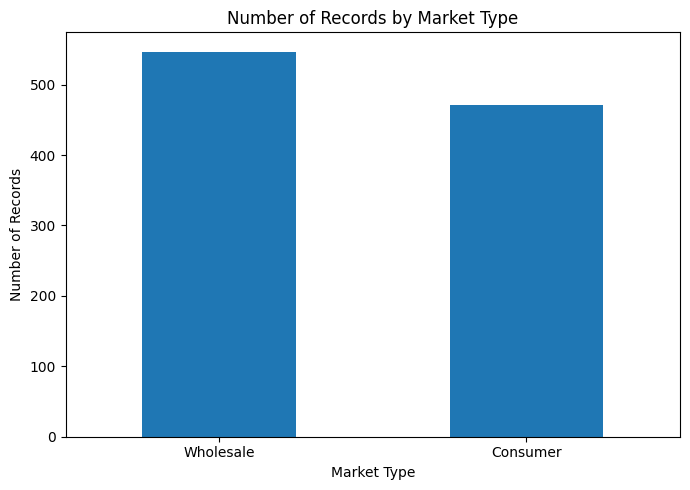

In [6]:
market_counts = df["MarketType"].value_counts()

plt.figure(figsize=(7,5))

market_counts.plot(kind="bar")

plt.title("Number of Records by Market Type")
plt.xlabel("Market Type")
plt.ylabel("Number of Records")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [7]:
print("Number of unique species:",
      df["Species"].nunique())

print("\nSpecies:")
for species in sorted(df["Species"].unique()):
    print(species)

Number of unique species: 31

Species:
Anchovy
Barracuda(L)
Big eye scade
Cuttle fish
Frigate tuna
Ginnati Paraw
Herrings
Indian Anchovies
Indian Mackerel
Indian Scad
Katuwalla
Kawakawa
Marlins
Needle fish
Pony fish
Prawns
Rainbow Runner
Red Bream(L)
Rock fish (L)
Rock fish (S)
Sail fish
Sardinella
Sea Crabs(L)
Seer
Shark
Skipjack tuna
Threadfin Bream
Tilapia
Trevally (L)
White Sardinella
Yellowfin tuna


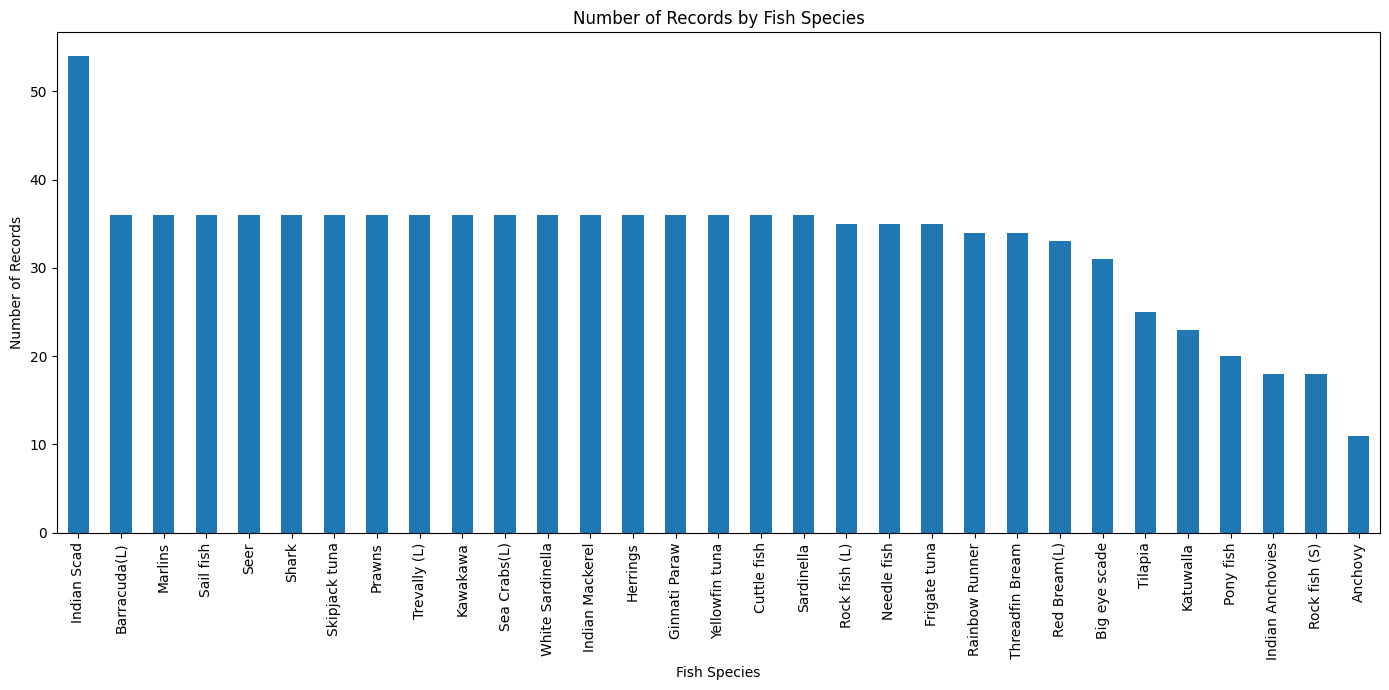

In [8]:
species_counts = df["Species"].value_counts()

plt.figure(figsize=(14,7))

species_counts.plot(kind="bar")

plt.title("Number of Records by Fish Species")
plt.xlabel("Fish Species")
plt.ylabel("Number of Records")
plt.xticks(rotation=90)

plt.tight_layout()
plt.show()

In [9]:
average_price = (
    df.groupby("Species")["Price_Current"]
    .mean()
    .sort_values(ascending=False)
)

print(average_price)

Species
Seer                3109.931667
Marlins             2842.506667
Sea Crabs(L)        2719.571111
Sail fish           2517.869444
Prawns              2253.895000
Yellowfin tuna      2197.469444
Cuttle fish         2108.141667
Trevally (L)        2084.723889
Rock fish (L)       2015.046000
Barracuda(L)        1965.712500
Shark               1759.025833
Indian Anchovies    1723.194444
Red Bream(L)        1614.755455
Skipjack tuna       1525.018056
Ginnati Paraw       1500.351389
Needle fish         1395.318000
Indian Mackerel     1368.933333
Kawakawa            1320.718056
Threadfin Bream     1284.845000
Frigate tuna        1146.246286
Herrings            1135.060833
Big eye scade       1131.048065
Rock fish (S)       1086.156667
Rainbow Runner      1021.950588
Indian Scad          993.495556
Sardinella           808.327222
Tilapia              612.342800
White Sardinella     607.539167
Anchovy              599.818182
Katuwalla            575.642609
Pony fish            305.760000


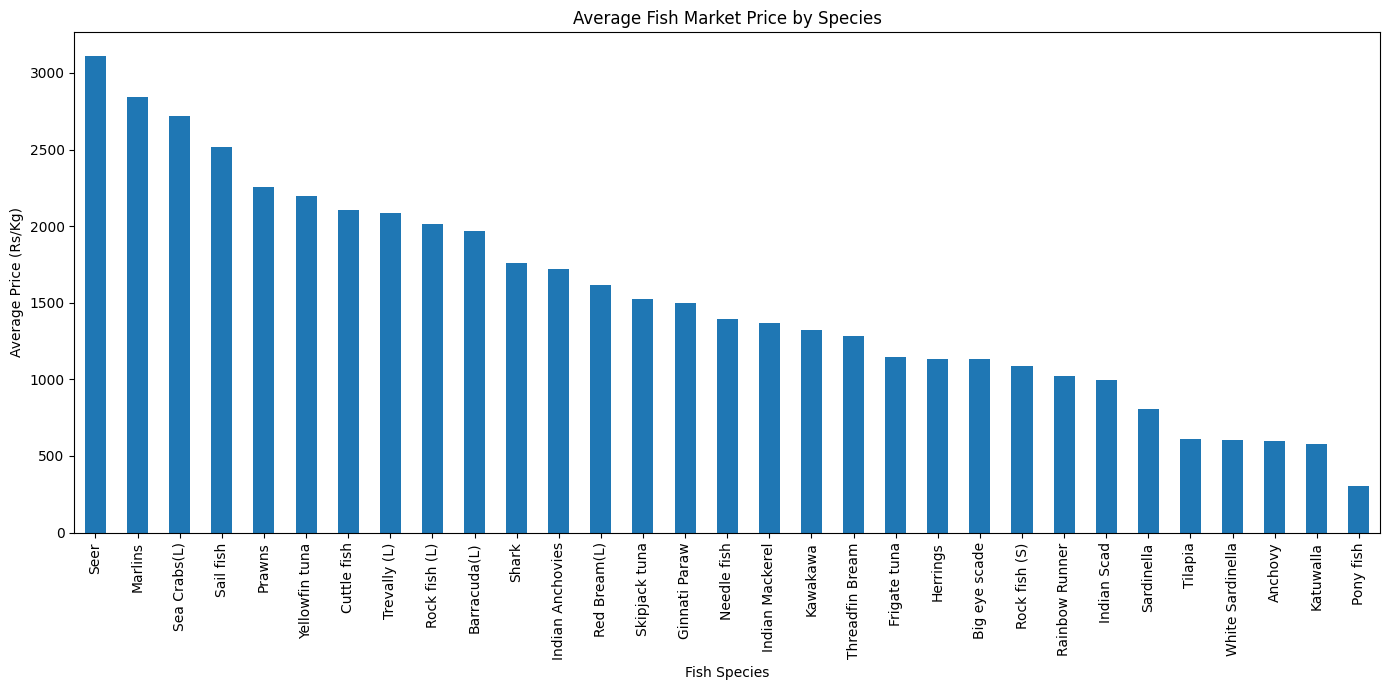

In [10]:
plt.figure(figsize=(14,7))

average_price.plot(kind="bar")

plt.title("Average Fish Market Price by Species")
plt.xlabel("Fish Species")
plt.ylabel("Average Price (Rs/Kg)")
plt.xticks(rotation=90)

plt.tight_layout()
plt.show()

In [11]:
market_price = (
    df.groupby("MarketType")["Price_Current"]
    .mean()
)

print(market_price)

MarketType
Consumer     1959.861953
Wholesale    1269.356691
Name: Price_Current, dtype: float64


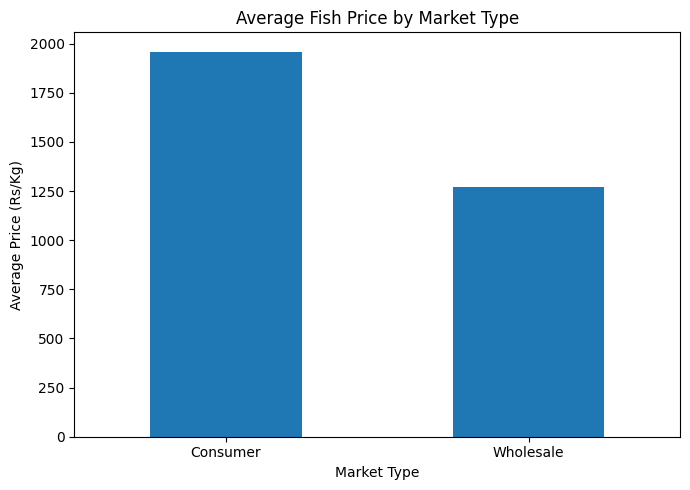

In [12]:
plt.figure(figsize=(7,5))

market_price.plot(kind="bar")

plt.title("Average Fish Price by Market Type")
plt.xlabel("Market Type")
plt.ylabel("Average Price (Rs/Kg)")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

In [19]:
print(df["Month"].unique())
print(df["Month"].value_counts())

['March', 'April', 'May', 'June', 'July']
Categories (6, object): ['JanuaryFebruary' < 'March' < 'April' < 'May' < 'June' < 'July']
Month
March              230
May                226
July               225
April              222
June               115
JanuaryFebruary      0
Name: count, dtype: int64


In [17]:
month_order = [
    "March",
    "April",
    "May",
    "June",
    "July"
]

df["Month"] = pd.Categorical(
    df["Month"],
    categories=month_order,
    ordered=True
)

In [18]:
monthly_price = (
    df.groupby("Month", observed=True)["Price_Current"]
    .mean()
)

print(monthly_price)

Month
March    1380.112478
April    1472.582973
May      1632.891858
June     1760.485130
July     1784.908667
Name: Price_Current, dtype: float64


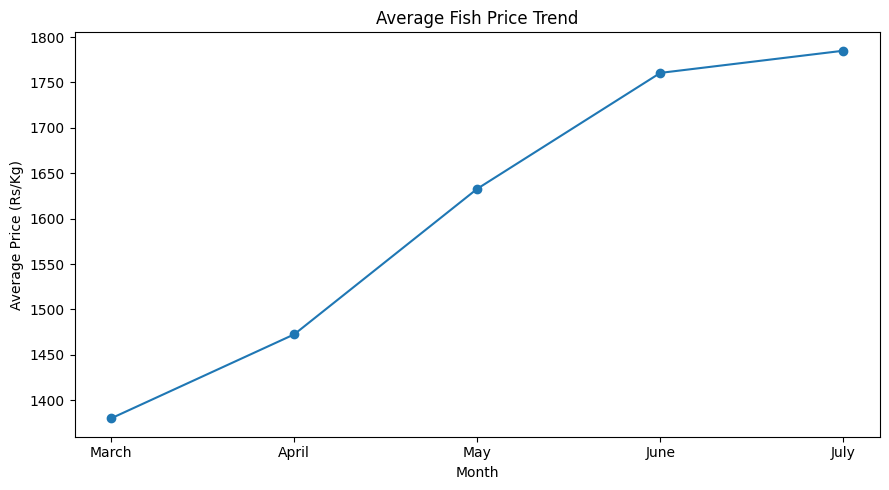

In [20]:
plt.figure(figsize=(9,5))

plt.plot(
    monthly_price.index,
    monthly_price.values,
    marker="o"
)

plt.title("Average Fish Price Trend")
plt.xlabel("Month")
plt.ylabel("Average Price (Rs/Kg)")

plt.tight_layout()
plt.show()

In [21]:
monthly_market = (
    df.groupby(
        ["Month", "MarketType"],
        observed=True
    )["Price_Current"]
    .mean()
    .unstack()
)

print(monthly_market)

MarketType     Consumer    Wholesale
Month                               
March       1712.570091  1075.359667
April       1782.449417  1204.379244
May         2005.440865  1315.309098
June        2081.957170  1485.678387
July        2299.112871  1366.081048


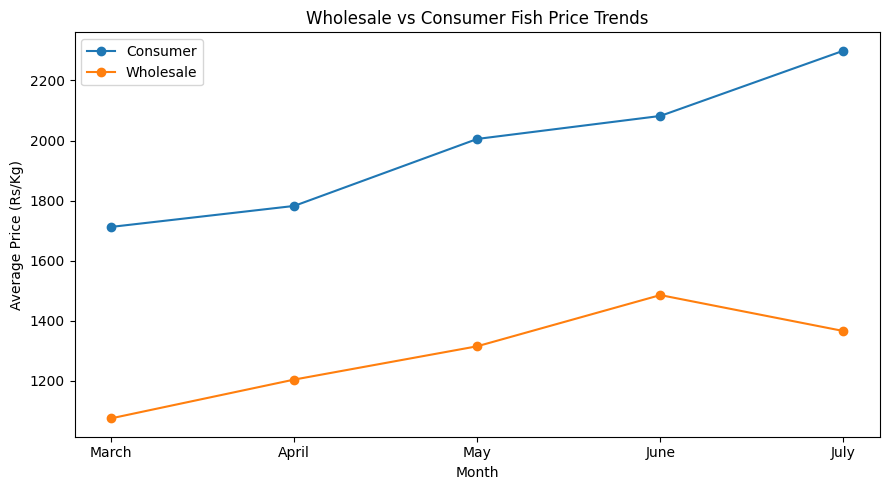

In [22]:
plt.figure(figsize=(9,5))

for market in monthly_market.columns:
    plt.plot(
        monthly_market.index,
        monthly_market[market],
        marker="o",
        label=market
    )

plt.title("Wholesale vs Consumer Fish Price Trends")
plt.xlabel("Month")
plt.ylabel("Average Price (Rs/Kg)")
plt.legend()

plt.tight_layout()
plt.show()

In [23]:
highest = (
    df.groupby("Species")["Price_Current"]
    .mean()
    .sort_values(ascending=False)
    .head(10)
)

print("Top 10 Most Expensive Fish:")
print(highest)

Top 10 Most Expensive Fish:
Species
Seer              3109.931667
Marlins           2842.506667
Sea Crabs(L)      2719.571111
Sail fish         2517.869444
Prawns            2253.895000
Yellowfin tuna    2197.469444
Cuttle fish       2108.141667
Trevally (L)      2084.723889
Rock fish (L)     2015.046000
Barracuda(L)      1965.712500
Name: Price_Current, dtype: float64


In [24]:
lowest = (
    df.groupby("Species")["Price_Current"]
    .mean()
    .sort_values()
    .head(10)
)

print("Top 10 Lowest-Priced Fish:")
print(lowest)

Top 10 Lowest-Priced Fish:
Species
Pony fish            305.760000
Katuwalla            575.642609
Anchovy              599.818182
White Sardinella     607.539167
Tilapia              612.342800
Sardinella           808.327222
Indian Scad          993.495556
Rainbow Runner      1021.950588
Rock fish (S)       1086.156667
Big eye scade       1131.048065
Name: Price_Current, dtype: float64


In [25]:
print(df[
    [
        "Price_2025",
        "Price_LastWeek",
        "Price_Current"
    ]
].describe())

        Price_2025  Price_LastWeek  Price_Current
count  1018.000000     1018.000000    1018.000000
mean   1433.759951     1634.309219    1588.834077
std     790.204571      819.611506     878.877828
min       3.000000      211.430000      -0.400000
25%     898.747500     1060.000000    1008.747500
50%    1260.000000     1474.165000    1456.665000
75%    1893.212500     2065.002500    2065.002500
max    4845.000000     4495.000000    4490.000000


In [26]:
print("Duplicate rows:",
      df.duplicated().sum())

Duplicate rows: 0


In [27]:
print(
    df[
        [
            "Price_2025",
            "Price_LastWeek",
            "Price_Current"
        ]
    ].corr()
)

                Price_2025  Price_LastWeek  Price_Current
Price_2025        1.000000        0.904787       0.839487
Price_LastWeek    0.904787        1.000000       0.919927
Price_Current     0.839487        0.919927       1.000000


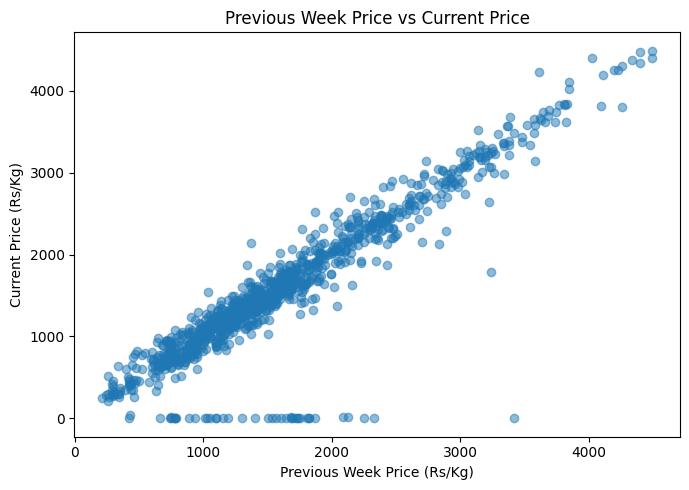

In [28]:
plt.figure(figsize=(7,5))

plt.scatter(
    df["Price_LastWeek"],
    df["Price_Current"],
    alpha=0.5
)

plt.title("Previous Week Price vs Current Price")
plt.xlabel("Previous Week Price (Rs/Kg)")
plt.ylabel("Current Price (Rs/Kg)")

plt.tight_layout()
plt.show()

In [29]:
X = df[
    [
        "Species",
        "MarketType",
        "Year",
        "Month",
        "Week",
        "Price_LastWeek",
        "Price_2025"
    ]
]

y = df["Price_Current"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (1018, 7)
y shape: (1018,)
